In [1]:
import sys
sys.path.append("..")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss

from src.models import logit

valid = pd.read_parquet("../data/processed/valid.parquet")
test = pd.read_parquet("../data/processed/test.parquet")
y_valid, y_test = valid["target"], test["target"]

lgbm = joblib.load("../models/lightgbm_v2.joblib")

raw_valid = lgbm.predict_proba(valid.drop(columns=["target"]))[:, 1]
raw_test = lgbm.predict_proba(test.drop(columns=["target"]))[:, 1]

print("Raw average predicted (test):", round(raw_test.mean(), 4))
print("Actual default rate (test):  ", round(y_test.mean(), 4))

Raw average predicted (test): 0.135
Actual default rate (test):   0.1471


In [2]:
platt = LogisticRegression()
platt.fit(logit(raw_valid).reshape(-1, 1), y_valid)

isotonic = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1)
isotonic.fit(raw_valid, y_valid)

p_test = {
    "Platt": platt.predict_proba(logit(raw_test).reshape(-1, 1))[:, 1],
    "Isotonic": isotonic.predict(raw_test),
}
p_valid = {
    "Platt": platt.predict_proba(logit(raw_valid).reshape(-1, 1))[:, 1],
    "Isotonic": isotonic.predict(raw_valid),
}
print("Both corrections fitted on validation.")

Both corrections fitted on validation.


In [3]:
def calibration_table(y_true, probabilities, groups=10):
    data = pd.DataFrame({"actual": np.asarray(y_true), "predicted": probabilities})
    data["group"] = pd.qcut(data["predicted"].rank(method="first"), q=groups, labels=False)
    return data.groupby("group").agg(
        loans=("actual", "size"),
        avg_predicted=("predicted", "mean"),
        actual_rate=("actual", "mean"),
    )


def calibration_error(y_true, probabilities):
    table = calibration_table(y_true, probabilities)
    gaps = (table["avg_predicted"] - table["actual_rate"]).abs()
    return (gaps * table["loans"]).sum() / table["loans"].sum()


results = pd.DataFrame({
    name: {
        "auc": roc_auc_score(y_test, p),
        "brier": brier_score_loss(y_test, p),
        "avg_predicted": p.mean(),
        "calibration_error": calibration_error(y_test, p),
    }
    for name, p in p_test.items()
}).T

print("Actual test default rate:", round(y_test.mean(), 4))
results.round(4)

Actual test default rate: 0.1471


,auc,brier,avg_predicted,calibration_error
Platt,0.7026,0.1170,0.1462,0.0037
Isotonic,0.7023,0.1171,0.1461,0.0034


In [4]:
deciles = pd.DataFrame({
    "loans": calibration_table(y_test, p_test["Platt"])["loans"],
    "actual_pct": calibration_table(y_test, p_test["Platt"])["actual_rate"] * 100,
    "platt_pct": calibration_table(y_test, p_test["Platt"])["avg_predicted"] * 100,
})
iso = calibration_table(y_test, p_test["Isotonic"])
deciles["isotonic_actual_pct"] = iso["actual_rate"] * 100
deciles["isotonic_pct"] = iso["avg_predicted"] * 100
deciles.index = [f"{i + 1}" + (" (safest)" if i == 0 else " (riskiest)" if i == 9 else "") for i in deciles.index]

deciles.round(2)

,loans,actual_pct,platt_pct,isotonic_actual_pct,isotonic_pct
1 (safest),16224,2.82,3.37,2.86,2.80
2,16224,5.29,5.84,5.34,5.52
3,16223,7.60,7.77,7.45,7.45
4,16224,9.54,9.64,9.57,9.33
5,16223,12.24,11.62,12.37,12.17
6,16224,14.21,13.83,14.02,14.62
7,16223,16.68,16.42,16.89,17.32
8,16224,20.25,19.62,20.08,19.68
9,16223,24.48,24.16,24.83,24.09
10 (riskiest),16224,33.99,33.92,33.68,33.12


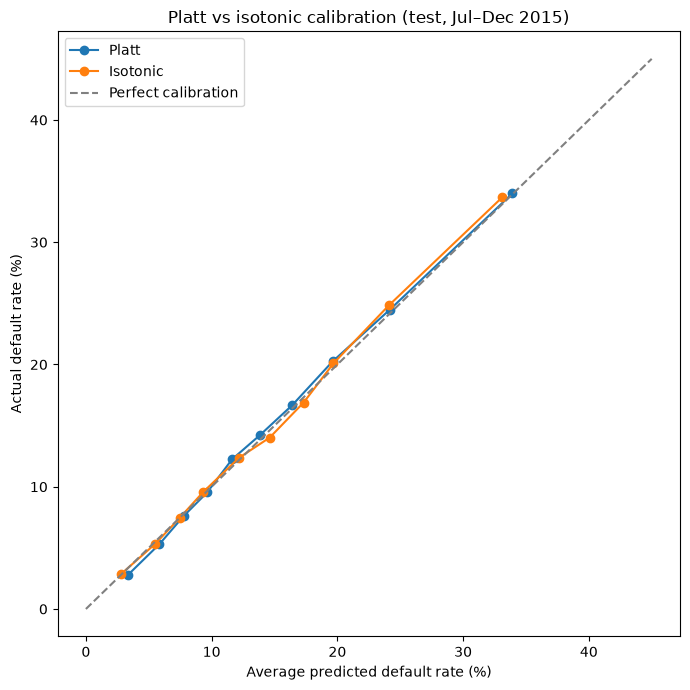

In [5]:
fig, ax = plt.subplots(figsize=(7, 7))
for name, p in p_test.items():
    table = calibration_table(y_test, p)
    ax.plot(table["avg_predicted"] * 100, table["actual_rate"] * 100, marker="o", label=name)

ax.plot([0, 45], [0, 45], linestyle="--", color="gray", label="Perfect calibration")
ax.set_xlabel("Average predicted default rate (%)")
ax.set_ylabel("Actual default rate (%)")
ax.set_title("Platt vs isotonic calibration (test, Jul–Dec 2015)")
ax.legend()

plt.tight_layout()
plt.savefig("../results/figures/calibration_platt_vs_isotonic.png", dpi=120)
plt.show()

In [6]:
profit_valid = (valid["total_pymnt"] - valid["funded_amnt"]).values
profit_test = (test["total_pymnt"] - test["funded_amnt"]).values
thresholds = np.round(np.arange(0.05, 0.605, 0.005), 3)

money = {}
for name in p_test:
    totals = [profit_valid[p_valid[name] < t].sum() for t in thresholds]
    cutoff = thresholds[int(np.argmax(totals))]
    approved = p_test[name] < cutoff
    money[name] = {
        "cutoff": cutoff,
        "approval_rate_pct": approved.mean() * 100,
        "gain_vs_approve_all": (profit_test[approved].sum() - profit_test.sum()) / 1e6,
    }

pd.DataFrame(money).T.round(3)

,cutoff,approval_rate_pct,gain_vs_approve_all
Platt,0.360,97.183,2.552
Isotonic,0.345,98.171,1.925


In [7]:
summary = results.join(pd.DataFrame(money).T)
summary.round(4).to_csv("../results/calibration_comparison.csv")
summary.round(4)

,auc,brier,avg_predicted,calibration_error,cutoff,approval_rate_pct,gain_vs_approve_all
Platt,0.7026,0.1170,0.1462,0.0037,0.360,97.1831,2.5517
Isotonic,0.7023,0.1171,0.1461,0.0034,0.345,98.1712,1.9255
